# 01 — Exploratory Data Analysis

**Goal:** understand the data before modelling. Every section ends with a *Takeaway* that feeds a decision later in the project.

| Section | Question | Decision it drives |
|---|---|---|
| 1 | Shape, types, nulls? | Do we need imputation? |
| 2 | Duplicates? | Drop before splitting (avoid train/test overlap) |
| 3 | How imbalanced? | Metrics (PR-AUC, not accuracy) and resampling |
| 4 | Amount by class | Scaling choice (RobustScaler) |
| 5 | Time / hour of day | Keep or drop Time |
| 6 | V1–V28 vs Class | Which features carry signal |

In [1]:
import sys
sys.path.append("..")   # so `src` is importable from notebooks/

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

from src.config import FIGURES_DIR, TARGET
from src.utils import load_raw

## 1. Load & inspect

In [2]:
df = load_raw()
print("Shape:", df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
print("Total missing values:", df.isnull().sum().sum())
df[["Time", "Amount", TARGET]].describe()

Total missing values: 0


,Time,Amount,Class
count,284807.0000,284807.0000,284807.0000
mean,94813.8596,88.3496,0.0017
std,47488.1460,250.1201,0.0415
min,0.0000,0.0000,0.0000
25%,54201.5000,5.6000,0.0000
50%,84692.0000,22.0000,0.0000
75%,139320.5000,77.1650,0.0000
max,172792.0000,25691.1600,1.0000


**Takeaway:** 31 columns, all numeric, no missing values → no imputation step needed.
`Time` = seconds since the first transaction (spans ~2 days). `Amount` is in euros.

## 2. Duplicates

In [5]:
dup_mask = df.duplicated()
print(f"Duplicate rows: {dup_mask.sum():,}")
print("Class breakdown of duplicates:")
print(df.loc[dup_mask, TARGET].value_counts())

Duplicate rows: 1,081
Class breakdown of duplicates:
Class
0    1062
1      19
Name: count, dtype: int64


**Takeaway:** there are exact duplicate rows. If one copy lands in train and the other in test, the model is tested on a row it has already seen → inflated scores. We drop them **before** the train/test split (in `02_baseline`).

## 3. Class imbalance — the core problem

In [6]:
counts = df[TARGET].value_counts()
ratio = df[TARGET].value_counts(normalize=True) * 100
summary = pd.DataFrame({"count": counts, "percent": ratio}).rename(index={0: "Legit (0)", 1: "Fraud (1)"})
print(summary)
print(f"\nImbalance ratio: 1 fraud per {counts[0] / counts[1]:.0f} legit transactions")
print(f"Accuracy of predicting 'legit' for everything: {ratio[0]:.2f}%")

            count  percent
Class                     
Legit (0)  284315  99.8273
Fraud (1)     492   0.1727

Imbalance ratio: 1 fraud per 578 legit transactions
Accuracy of predicting 'legit' for everything: 99.83%


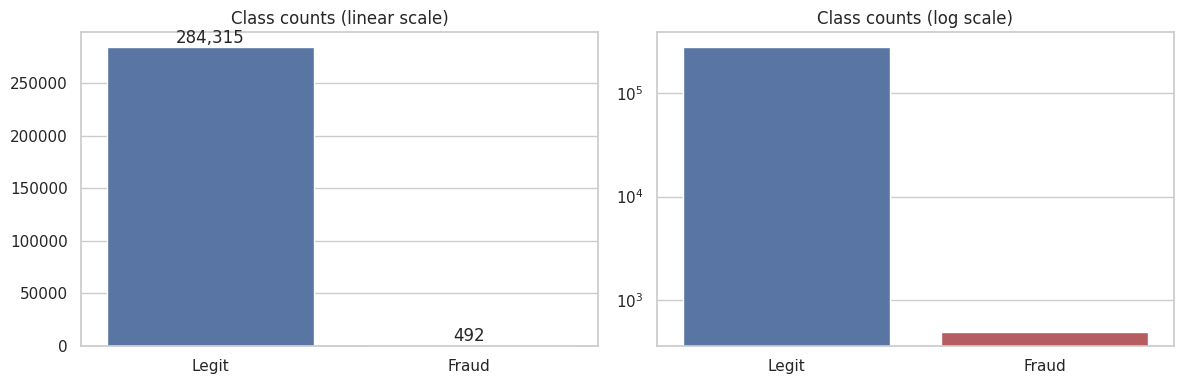

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x=["Legit", "Fraud"], y=counts.values, ax=axes[0], palette=["#4C72B0", "#C44E52"])
axes[0].set_title("Class counts (linear scale)")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

sns.barplot(x=["Legit", "Fraud"], y=counts.values, ax=axes[1], palette=["#4C72B0", "#C44E52"])
axes[1].set_yscale("log")
axes[1].set_title("Class counts (log scale)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_class_balance.png", dpi=120, bbox_inches="tight")
plt.show()

**Takeaway:** ~0.17% fraud. A model that always says "legit" scores ~99.8% accuracy and catches nothing.
→ We evaluate with **Precision, Recall, F1 and PR-AUC**, and we test imbalance-handling techniques in `03`.

## 4. Transaction amount by class

In [8]:
df.groupby(TARGET)["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0000,88.2910,250.1051,0.0000,5.6500,22.0000,77.0500,25691.1600
1,492.0000,122.2113,256.6833,0.0000,1.0000,9.2500,105.8900,2125.8700


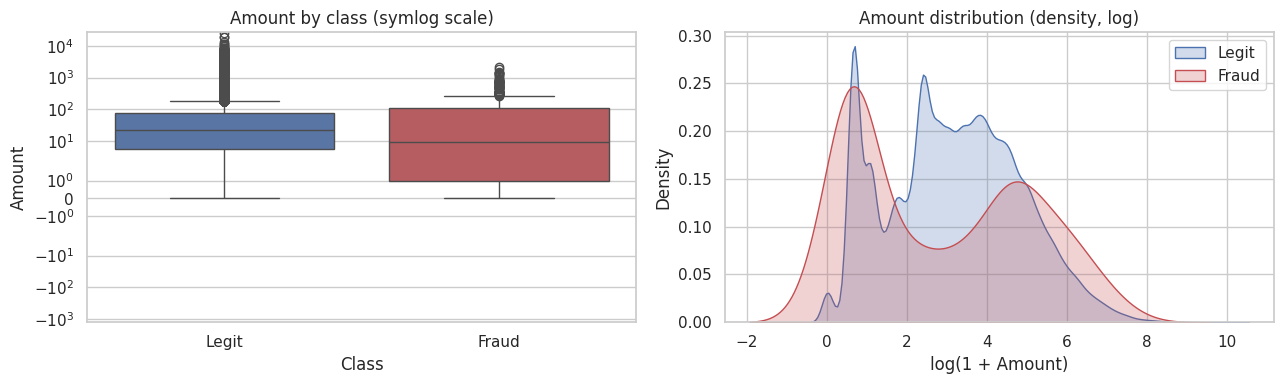

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(data=df, x=TARGET, y="Amount", ax=axes[0], palette=["#4C72B0", "#C44E52"])
axes[0].set_yscale("symlog")
axes[0].set_title("Amount by class (symlog scale)")
axes[0].set_xticklabels(["Legit", "Fraud"])

for cls, color, label in [(0, "#4C72B0", "Legit"), (1, "#C44E52", "Fraud")]:
    sns.kdeplot(np.log1p(df.loc[df[TARGET] == cls, "Amount"]), ax=axes[1],
                color=color, label=label, fill=True, common_norm=False)
axes[1].set_xlabel("log(1 + Amount)")
axes[1].set_title("Amount distribution (density, log)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_amount_by_class.png", dpi=120, bbox_inches="tight")
plt.show()

In [10]:
q = df["Amount"].quantile([0.5, 0.99, 0.999])
print(f"Median: {q[0.5]:.2f}  |  99th pct: {q[0.99]:.2f}  |  99.9th pct: {q[0.999]:.2f}  |  Max: {df['Amount'].max():.2f}")

Median: 22.00  |  99th pct: 1017.97  |  99.9th pct: 3000.00  |  Max: 25691.16


**Takeaway:** most fraud amounts are *small* — fraudsters often test cards with low-value transactions. Amount is heavily right-skewed with extreme outliers (max is far above the 99.9th percentile).
→ We use **RobustScaler** (median / IQR) instead of StandardScaler (mean / std), because outliers would distort the mean and std.

## 5. Time — does fraud cluster at certain hours?

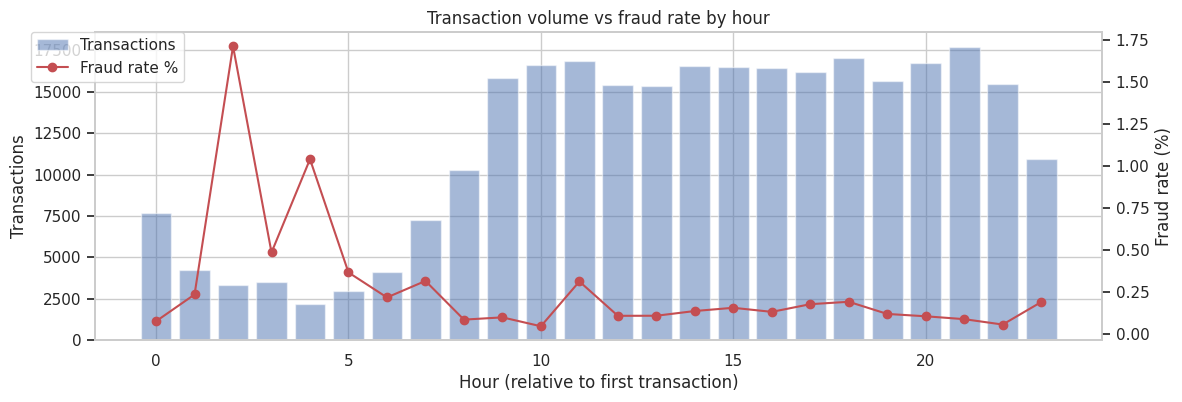

,transactions,frauds,fraud_rate_%
Hour,,,
2.0000,3328,57,1.7127
4.0000,2209,23,1.0412
3.0000,3492,17,0.4868
5.0000,2990,11,0.3679
7.0000,7243,23,0.3175


In [11]:
df["Hour"] = (df["Time"] // 3600) % 24

hourly = df.groupby("Hour")[TARGET].agg(transactions="count", frauds="sum")
hourly["fraud_rate_%"] = hourly["frauds"] / hourly["transactions"] * 100

fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.bar(hourly.index, hourly["transactions"], color="#4C72B0", alpha=0.5, label="Transactions")
ax1.set_xlabel("Hour (relative to first transaction)")
ax1.set_ylabel("Transactions")
ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly["fraud_rate_%"], color="#C44E52", marker="o", label="Fraud rate %")
ax2.set_ylabel("Fraud rate (%)")
ax2.grid(False)
plt.title("Transaction volume vs fraud rate by hour")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.9))
plt.savefig(FIGURES_DIR / "01_fraud_by_hour.png", dpi=120, bbox_inches="tight")
plt.show()

hourly.sort_values("fraud_rate_%", ascending=False).head(5)

**Takeaway:** transaction volume drops sharply during the "night" hours, while the fraud *rate* rises then — fewer legit transactions, similar fraud activity.
Caveat: `Time` only covers ~2 days and the "hour" is relative to the first transaction, not a real clock. We keep `Time` (scaled) as a feature but don't over-engineer it.

In [12]:
df = df.drop(columns="Hour")   # EDA-only helper column

## 6. PCA features V1–V28 — which ones separate fraud?

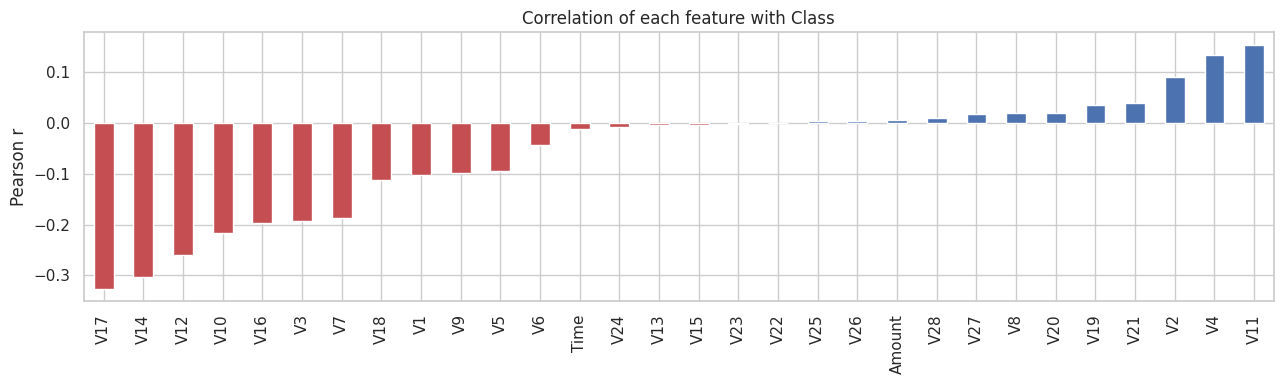

Strongest features (|r|): ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']


In [13]:
corr = df.drop(columns=TARGET).corrwith(df[TARGET]).sort_values()

plt.figure(figsize=(13, 4))
colors = ["#C44E52" if c < 0 else "#4C72B0" for c in corr.values]
corr.plot(kind="bar", color=colors)
plt.title("Correlation of each feature with Class")
plt.ylabel("Pearson r")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_feature_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

top_features = corr.abs().sort_values(ascending=False).head(6).index.tolist()
print("Strongest features (|r|):", top_features)

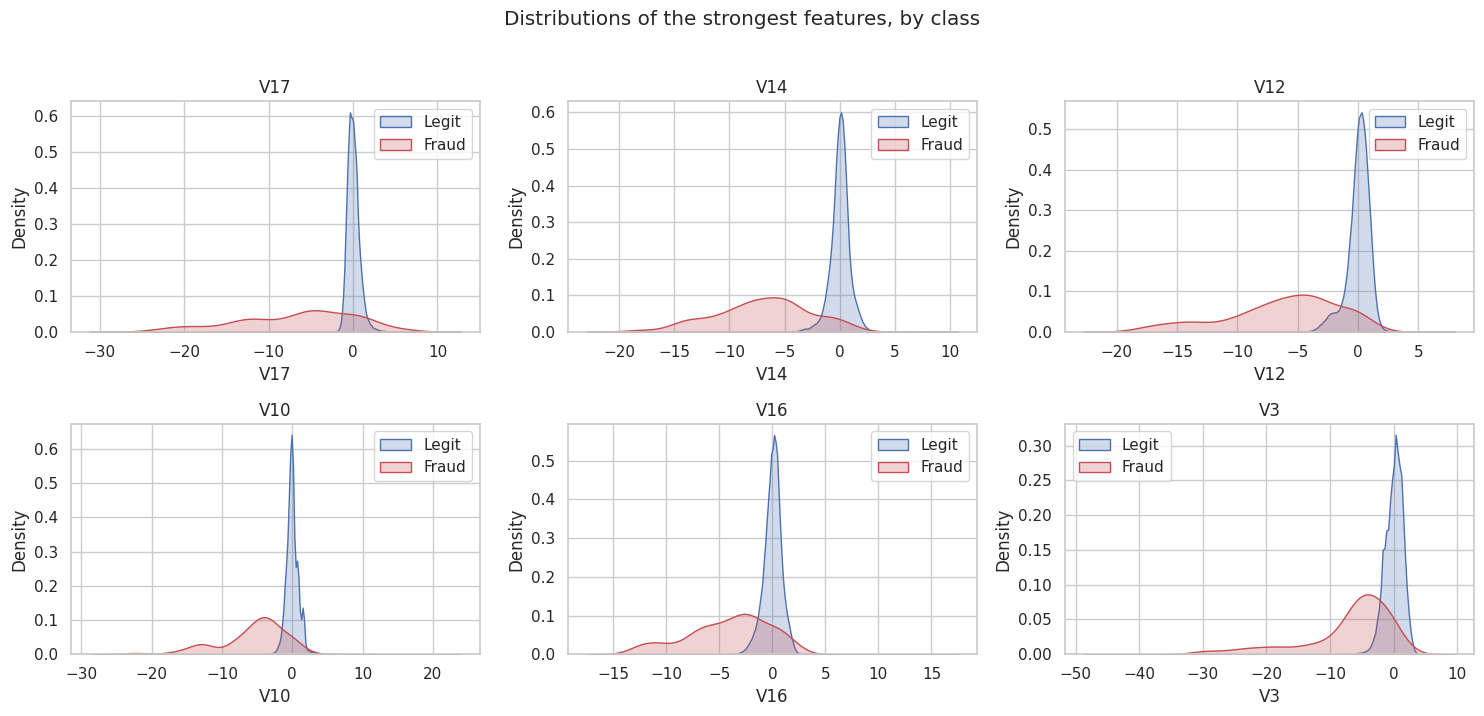

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, feat in zip(axes.ravel(), top_features):
    for cls, color, label in [(0, "#4C72B0", "Legit"), (1, "#C44E52", "Fraud")]:
        sns.kdeplot(df.loc[df[TARGET] == cls, feat], ax=ax, color=color, label=label,
                    fill=True, common_norm=False, warn_singular=False)
    ax.set_title(feat)
    ax.legend()
plt.suptitle("Distributions of the strongest features, by class", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_top_feature_kde.png", dpi=120, bbox_inches="tight")
plt.show()

In [15]:
# PCA components should be (nearly) uncorrelated with each other - sanity check
v_cols = [f"V{i}" for i in range(1, 29)]
off_diag = df[v_cols].corr().abs().values[np.triu_indices(28, k=1)]
print(f"Max |correlation| between any two V-features: {off_diag.max():.3f}")

Max |correlation| between any two V-features: 0.000


**Takeaway:** a handful of components (typically V14, V17, V12, V10) show clearly different distributions for fraud vs legit — that's where most of the signal is. The V-features are uncorrelated with each other (as PCA guarantees), so multicollinearity is not a concern.

Note: Pearson correlation only measures *linear* relationships. Tree models (RF / XGBoost) can also use non-linear signal that this plot misses.

## Summary → decisions for modelling

1. **No nulls** → no imputation.
2. **Duplicates exist** → drop them before splitting.
3. **~0.17% fraud** → accuracy is meaningless; primary metric = **PR-AUC**, plus precision / recall / F1.
4. **Stratified split** so train and test keep the same fraud ratio.
5. **Scale only Time and Amount**, with RobustScaler, fitted **on training data only** (inside a pipeline).
6. Imbalance techniques to benchmark: class weights, undersampling, SMOTE — applied **inside CV folds** only.